# Tugas 1 — Audit Data dan Exploratory Data Analysis

Visualisasi Data Lanjut (CAK7AGB4) · NIM 203012420009

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Baca data mentah (path relatif)
df = pd.read_csv("../data/203012420009_layanan.csv")
df.shape

(4100, 12)

## Bagian A — Audit kualitas data

In [3]:
# Gambaran umum
df.info()
df.describe(include="all").T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4100 entries, 0 to 4099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_transaksi        4100 non-null   object 
 1   tanggal             4100 non-null   object 
 2   cabang              4100 non-null   object 
 3   kategori_produk     4100 non-null   object 
 4   kanal               4100 non-null   object 
 5   jumlah_unit         4100 non-null   int64  
 6   harga_satuan        4100 non-null   float64
 7   diskon_persen       4100 non-null   int64  
 8   rating_pelanggan    3995 non-null   float64
 9   waktu_proses_menit  4100 non-null   float64
 10  status              4100 non-null   object 
 11  total_transaksi     4100 non-null   float64
dtypes: float64(4), int64(2), object(6)
memory usage: 384.5+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id_transaksi,4100,3996,TRX001377,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tanggal,4100,615,2025-07-16,22,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cabang,4100,8,Cirebon,538,NaN,NaN,NaN,NaN,NaN,NaN,NaN
kategori_produk,4100,5,Perawatan Diri,1093,NaN,NaN,NaN,NaN,NaN,NaN,NaN
kanal,4100,11,Online,2037,NaN,NaN,NaN,NaN,NaN,NaN,NaN
jumlah_unit,4100.0,NaN,NaN,NaN,4.060976,9.461943,0.0,2.0,3.0,4.0,118.0
harga_satuan,4100.0,NaN,NaN,NaN,310590.212,581707.950028,20.0,28200.0,67100.0,300500.0,2342900.0
diskon_persen,4100.0,NaN,NaN,NaN,4.362195,6.80931,0.0,0.0,0.0,10.0,20.0
rating_pelanggan,3995.0,NaN,NaN,NaN,42.915895,193.397682,1.0,3.0,4.0,4.0,999.0
waktu_proses_menit,4100.0,NaN,NaN,NaN,46.954902,563.716744,-22.8,12.4,24.8,39.9,18487.0


### A1. Nilai hilang

In [4]:
# Jumlah dan persentase nilai kosong per kolom
hilang = df.isna().sum()
pd.DataFrame({"jumlah": hilang, "persen": (hilang / len(df) * 100).round(2)})

,jumlah,persen
id_transaksi,0,0.00
tanggal,0,0.00
cabang,0,0.00
kategori_produk,0,0.00
kanal,0,0.00
jumlah_unit,0,0.00
harga_satuan,0,0.00
diskon_persen,0,0.00
rating_pelanggan,105,2.56
waktu_proses_menit,0,0.00


In [5]:
# Nilai terkecil dan terbesar tiap kolom numerik
for k in df.select_dtypes("number").columns:
    unik = np.sort(df[k].dropna().unique())
    print(f"{k}: {len(unik)} nilai unik | terkecil {unik[:5]} | terbesar {unik[-5:]}")

jumlah_unit: 46 nilai unik | terkecil [0 1 2 3 4] | terbesar [105 112 115 116 118]
harga_satuan: 1897 nilai unik | terkecil [20.  23.1 23.3 23.5 24. ] | terbesar [2155600. 2156800. 2168800. 2214700. 2342900.]
diskon_persen: 5 nilai unik | terkecil [ 0  5 10 15 20] | terbesar [ 0  5 10 15 20]
rating_pelanggan: 6 nilai unik | terkecil [1. 2. 3. 4. 5.] | terbesar [  2.   3.   4.   5. 999.]
waktu_proses_menit: 703 nilai unik | terkecil [-22.8 -18.8 -18.3 -18.1 -16.6] | terbesar [11378.6 12992.9 18050.5 18474.5 18487. ]
total_transaksi: 3300 nilai unik | terkecil [20.   21.68 22.88 22.99 23.3 ] | terbesar [1.2758328e+08 1.4474380e+08 1.5784410e+08 1.6680480e+08 1.9441600e+08]


### A2. Duplikasi

In [6]:
# Baris duplikat persis
df.duplicated().sum()

58

In [7]:
# id_transaksi yang muncul lebih dari sekali
id_ganda = df[df.duplicated("id_transaksi", keep=False)].sort_values("id_transaksi")
print(id_ganda["id_transaksi"].nunique(), "id,", len(id_ganda), "baris")
id_ganda.head(10)

102 id, 206 baris


,id_transaksi,tanggal,cabang,kategori_produk,kanal,jumlah_unit,harga_satuan,diskon_persen,rating_pelanggan,waktu_proses_menit,status,total_transaksi
1683,TRX000001,2025-03-24,Cimahi,Peralatan Rumah,Offline,4,379000.0,0,4.0,26.9,Selesai,1516000.0
3085,TRX000001,2025-03-24,Cimahi,Peralatan Rumah,Offline,4,379000.0,0,4.0,26.9,Selesai,1516000.0
2123,TRX000166,2025-04-04,Sumedang,Elektronik,Online,5,1945400.0,0,5.0,22.8,Selesai,9727000.0
47,TRX000166,2025-04-04,Sumedang,Elektronik,Online,5,1945400.0,0,5.0,23.5,Selesai,9727000.0
2481,TRX000296,2025-05-17,Bogor,Makanan Kering,Online,1,26900.0,20,NaN,6.0,Selesai,21520.0
3416,TRX000296,2025-05-17,Bogor,Makanan Kering,Online,1,26900.0,20,NaN,6.0,Selesai,21520.0
3195,TRX000365,2025-08-05,Sumedang,Perawatan Diri,Offline,1,66300.0,0,3.0,36.5,Selesai,66300.0
3669,TRX000365,2025-08-05,Sumedang,Perawatan Diri,Offline,1,66300.0,0,3.0,36.5,Selesai,66300.0
101,TRX000419,2025-04-07,Bandung,Makanan Kering,online,5,32400.0,0,4.0,12.8,Selesai,162000.0
2459,TRX000419,2025-04-07,Bandung,Makanan Kering,online,5,32400.0,0,4.0,12.8,Selesai,162000.0


### A3. Konsistensi penulisan kategori

In [8]:
# Daftar nilai tiap kolom kategori
for k in ["cabang", "kategori_produk", "kanal", "status"]:
    print(df[k].value_counts(dropna=False), "\n")

cabang
Cirebon        538
Bekasi         531
Cimahi         525
Garut          517
Bogor          504
Sumedang       504
Tasikmalaya    501
Bandung        480
Name: count, dtype: int64 

kategori_produk
Perawatan Diri     1093
Makanan Kering     1004
Peralatan Rumah     758
Aksesori            657
Elektronik          588
Name: count, dtype: int64 

kanal
Online      2037
Offline     1803
online        35
 Online       33
ONLINE        31
OFFLINE       31
 offline      28
Daring        27
Luring        27
on-line       25
offline       23
Name: count, dtype: int64 

status
Selesai    3702
Batal       224
Pending     174
Name: count, dtype: int64 



In [9]:
# Format tanggal: baris yang memakai garis miring
miring = df.loc[df["tanggal"].str.contains("/"), "tanggal"].str.split("/", expand=True).astype(int)
print(len(miring), "baris | nilai maksimum tiap bagian:", miring.max().tolist())
df["tanggal"].sample(10, random_state=1).tolist()

376 baris | nilai maksimum tiap bagian: [31, 12, 2025]


['2025-10-22',
 '2025-06-15',
 '2025-09-16',
 '2025-07-09',
 '2025-08-21',
 '2025-04-14',
 '2025-10-01',
 '2025-05-07',
 '2025-05-22',
 '01/08/2025']

### A4. Nilai mustahil / di luar rentang wajar

In [10]:
# Jumlah nilai negatif dan nol tiap kolom numerik
num = df.select_dtypes("number")
pd.DataFrame({"negatif": (num < 0).sum(), "nol": (num == 0).sum()})

,negatif,nol
jumlah_unit,0,12
harga_satuan,0,0
diskon_persen,0,2669
rating_pelanggan,0,0
waktu_proses_menit,15,0
total_transaksi,0,0


In [11]:
# Sebaran nilai kolom numerik yang diskret
for k in ["jumlah_unit", "diskon_persen", "rating_pelanggan"]:
    print(df[k].value_counts(dropna=False).sort_index(), "\n")

jumlah_unit
0       12
1      828
2      771
3      832
4      775
5      825
40       1
43       1
45       1
48       1
50       3
51       1
54       1
56       1
58       1
59       1
60       1
62       1
64       2
65       1
66       1
69       1
75       1
76       2
78       3
79       2
80       1
81       3
83       2
84       1
85       1
87       1
88       1
89       2
90       2
92       2
93       1
96       1
99       1
100      1
104      2
105      1
112      1
115      2
116      2
118      2
Name: count, dtype: int64 

diskon_persen
0     2669
5      358
10     354
15     365
20     354
Name: count, dtype: int64 

rating_pelanggan
1.0         5
2.0       158
3.0      1133
4.0      1824
5.0       718
999.0     157
NaN       105
Name: count, dtype: int64 



In [12]:
# Rentang tanggal, dibaca dengan kedua format
iso = pd.to_datetime(df["tanggal"], format="%Y-%m-%d", errors="coerce")
lain = pd.to_datetime(df["tanggal"], format="%d/%m/%Y", errors="coerce")
tgl = iso.fillna(lain)
print(tgl.min().date(), "s.d.", tgl.max().date(), "| gagal dibaca:", tgl.isna().sum())
tgl.dt.year.value_counts()

2025-01-01 s.d. 2027-12-02 | gagal dibaca: 0


tanggal
2025    4085
2027      15
Name: count, dtype: int64

In [13]:
# Konsistensi total_transaksi dengan jumlah_unit x harga_satuan x (1 - diskon)
ada_unit = df[df["jumlah_unit"] > 0]
hitung = ada_unit["jumlah_unit"] * ada_unit["harga_satuan"] * (1 - ada_unit["diskon_persen"] / 100)
tak_cocok = ~np.isclose(hitung, ada_unit["total_transaksi"], rtol=1e-3)
print("Tidak cocok:", tak_cocok.sum(), f"baris ({tak_cocok.sum() / len(df) * 100:.1f}%)")
(ada_unit["total_transaksi"] / hitung)[tak_cocok].describe().round(2)

Tidak cocok: 59 baris (1.4%)


count    59.00
mean      1.82
std       0.33
min       1.21
25%       1.57
50%       1.85
75%       2.10
max       2.38
dtype: float64

### A5. Keseragaman satuan

In [14]:
# Median kolom numerik per kelompok
kolom = ["harga_satuan", "total_transaksi", "waktu_proses_menit"]
for g in ["cabang", "kategori_produk", "kanal"]:
    display(df.groupby(g, dropna=False)[kolom].median().round(1))

,harga_satuan,total_transaksi,waktu_proses_menit
cabang,,,
Bandung,69400.0,245750.0,26.8
Bekasi,73200.0,263200.0,23.9
Bogor,71650.0,219760.0,23.5
Cimahi,85200.0,236880.0,22.4
Cirebon,84.2,253.3,26.6
Garut,74400.0,256000.0,25.5
Sumedang,71700.0,268800.0,25.4
Tasikmalaya,70900.0,216600.0,24.2


,harga_satuan,total_transaksi,waktu_proses_menit
kategori_produk,,,
Aksesori,93300.0,236880.0,13.6
Elektronik,1812300.0,4981950.0,38.2
Makanan Kering,27600.0,72277.5,15.6
Peralatan Rumah,317550.0,800190.0,35.9
Perawatan Diri,63800.0,160320.0,26.5


,harga_satuan,total_transaksi,waktu_proses_menit
kanal,,,
Online,58200.0,97240.0,13.6
offline,304200.0,712200.0,42.0
Daring,62600.0,152000.0,13.0
Luring,288100.0,288100.0,41.9
OFFLINE,98100.0,330800.0,45.4
ONLINE,61600.0,114400.0,13.3
Offline,99500.0,325500.0,40.5
Online,60900.0,119600.0,13.0
offline,287700.0,312500.0,31.5


### A6. Pencilan

In [15]:
# Jumlah nilai di luar batas 1,5 x IQR tiap kolom numerik
q1, q3 = num.quantile(0.25), num.quantile(0.75)
iqr = q3 - q1
bawah, atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
pd.DataFrame({
    "batas_bawah": bawah.round(1), "batas_atas": atas.round(1),
    "di_bawah": (num < bawah).sum(), "di_atas": (num > atas).sum(),
})

,batas_bawah,batas_atas,di_bawah,di_atas
jumlah_unit,-1.0,7.0,0,57
harga_satuan,-380250.0,708950.0,0,501
diskon_persen,-15.0,25.0,0,0
rating_pelanggan,1.5,5.5,5,157
waktu_proses_menit,-28.8,81.2,0,23
total_transaksi,-735165.0,1403355.0,0,660


### Pembersihan

In [16]:
# Bantu hitung dampak: jumlah baris dan persentase terhadap total
def dampak(mask):
    return f"{mask.sum()} baris ({mask.mean() * 100:.1f}%)"

In [17]:
# Semua keputusan pembersihan diterapkan di sini
df_bersih = df.copy()

In [18]:
# 1. Seragamkan kanal menjadi Online / Offline
def seragam_kanal(s):
    s = s.str.strip().str.lower().str.replace("-", "")
    return s.replace({"daring": "online", "luring": "offline"}).str.capitalize()

print("Penulisan kanal tidak baku (data mentah):", dampak(df["kanal"] != seragam_kanal(df["kanal"])))
df_bersih["kanal"] = seragam_kanal(df_bersih["kanal"])
df_bersih["kanal"].value_counts(dropna=False)

Penulisan kanal tidak baku (data mentah): 260 baris (6.3%)


kanal
Online     2188
Offline    1912
Name: count, dtype: int64

In [19]:
# 2. Seragamkan tanggal (yyyy-mm-dd dan dd/mm/yyyy) menjadi datetime
def seragam_tanggal(s):
    iso = pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
    lain = pd.to_datetime(s, format="%d/%m/%Y", errors="coerce")
    return iso.fillna(lain)

print("Format tanggal dd/mm/yyyy (data mentah):", dampak(df["tanggal"].str.contains("/")))
df_bersih["tanggal"] = seragam_tanggal(df_bersih["tanggal"])
print("Gagal dibaca:", df_bersih["tanggal"].isna().sum())
df_bersih["tanggal"].dtype

Format tanggal dd/mm/yyyy (data mentah): 376 baris (9.2%)
Gagal dibaca: 0


dtype('<M8[ns]')

In [20]:
# 3. Hapus duplikat persis (setelah kanal dan tanggal seragam), sisakan satu baris
dup_persis = df_bersih.duplicated()
print("Duplikat persis:", dampak(dup_persis))
df_bersih = df_bersih[~dup_persis].reset_index(drop=True)
df_bersih.shape

Duplikat persis: 65 baris (1.6%)


(4035, 12)

In [21]:
# Sisa id_transaksi ganda dan kolom yang isinya berbeda
sisa = df_bersih[df_bersih.duplicated("id_transaksi", keep=False)].sort_values("id_transaksi")
print(sisa["id_transaksi"].nunique(), "id,", len(sisa), "baris")
sisa.groupby("id_transaksi").nunique(dropna=False).gt(1).sum()

39 id, 78 baris


tanggal                1
cabang                 0
kategori_produk        0
kanal                  0
jumlah_unit            0
harga_satuan           0
diskon_persen          0
rating_pelanggan       0
waktu_proses_menit    39
status                 0
total_transaksi        0
dtype: int64

In [22]:
# 4. id_transaksi ganda dengan isi berbeda: utamakan baris bertanggal valid, lalu baris pertama
BATAS_BULAN = pd.Period("2026-10", freq="M")  # bulan pengerjaan; bulan sesudahnya dianggap tidak valid
tgl_valid = df_bersih["tanggal"].dt.to_period("M") <= BATAS_BULAN
urut = df_bersih.assign(tgl_valid=tgl_valid).sort_values("tgl_valid", ascending=False, kind="stable")
dibuang = urut.duplicated("id_transaksi", keep="first").sort_index()
print(f"Baris id ganda yang dibuang: {dibuang.sum()} baris ({dibuang.sum() / len(df) * 100:.1f}% dari data mentah)")
print("  di antaranya bertanggal tidak valid:", (dibuang & ~tgl_valid).sum())
df_bersih = df_bersih[~dibuang].reset_index(drop=True)
print("id_transaksi unik:", df_bersih["id_transaksi"].is_unique, "|", df_bersih.shape)
print("Sisa baris bertanggal setelah batas:", (df_bersih["tanggal"].dt.to_period("M") > BATAS_BULAN).sum())

Baris id ganda yang dibuang: 39 baris (1.0% dari data mentah)
  di antaranya bertanggal tidak valid: 1
id_transaksi unik: True | (3996, 12)
Sisa baris bertanggal setelah batas: 14


In [23]:
# 5. jumlah_unit = 0 diisi dari total_transaksi / (harga_satuan x (1 - diskon))
print("jumlah_unit bernilai 0 (data mentah):", dampak(df["jumlah_unit"] == 0))
nol = df_bersih["jumlah_unit"] == 0
unit = df_bersih["total_transaksi"] / (df_bersih["harga_satuan"] * (1 - df_bersih["diskon_persen"] / 100))
df_bersih.loc[nol, "jumlah_unit"] = unit[nol].round().astype(int)
df_bersih.loc[nol, ["id_transaksi", "harga_satuan", "diskon_persen", "total_transaksi", "jumlah_unit"]]

jumlah_unit bernilai 0 (data mentah): 12 baris (0.3%)


,id_transaksi,harga_satuan,diskon_persen,total_transaksi,jumlah_unit
34,TRX003377,1824800.0,0,1824800.00,1
288,TRX002702,332000.0,0,664000.00,2
339,TRX000749,1899.6,10,5128.92,3
358,TRX000176,71600.0,0,286400.00,4
382,TRX001900,1891300.0,0,9456500.00,5
406,TRX001798,316.9,10,1426.05,5
426,TRX002825,1849500.0,0,7398000.00,4
888,TRX003286,58500.0,0,117000.00,2
2087,TRX002196,60700.0,0,121400.00,2
2891,TRX002232,60800.0,20,145920.00,3


In [24]:
# 6. waktu_proses_menit negatif dijadikan nilai hilang (baris tetap dipakai)
print("waktu_proses_menit negatif (data mentah):", dampak(df["waktu_proses_menit"] < 0))
negatif = df_bersih["waktu_proses_menit"] < 0
df_bersih.loc[negatif, "waktu_proses_menit"] = np.nan
print("Diubah di df_bersih:", negatif.sum(), "| minimum sekarang:", df_bersih["waktu_proses_menit"].min())

waktu_proses_menit negatif (data mentah): 15 baris (0.4%)
Diubah di df_bersih: 15 | minimum sekarang: 3.1


In [25]:
# 7. rating_pelanggan 999 (penanda tidak ada rating) dijadikan nilai hilang
print("rating 999 (data mentah):", dampak(df["rating_pelanggan"] == 999))
print("rating kosong (data mentah):", dampak(df["rating_pelanggan"].isna()))
df_bersih["rating_pelanggan"] = df_bersih["rating_pelanggan"].replace(999, np.nan)
print("Tanpa rating di df_bersih:", dampak(df_bersih["rating_pelanggan"].isna()))
df_bersih["rating_pelanggan"].value_counts(dropna=False).sort_index()

rating 999 (data mentah): 157 baris (3.8%)
rating kosong (data mentah): 105 baris (2.6%)
Tanpa rating di df_bersih: 256 baris (6.4%)


rating_pelanggan
1.0       5
2.0     153
3.0    1100
4.0    1783
5.0     699
NaN     256
Name: count, dtype: int64

In [26]:
# 8. Cabang Cirebon mencatat harga dalam ribuan rupiah: konversi ke rupiah (x 1.000)
kolom_rupiah = ["harga_satuan", "total_transaksi"]
print("Baris cabang Cirebon (data mentah):", dampak(df["cabang"] == "Cirebon"))
cirebon = df_bersih["cabang"] == "Cirebon"
median_kat = df_bersih.groupby(["kategori_produk", cirebon])["harga_satuan"].median().unstack()
print("Rasio median harga_satuan cabang lain / Cirebon, per kategori:",
      (median_kat[False] / median_kat[True]).round().astype(int).tolist())
df_bersih.loc[cirebon, kolom_rupiah] = df_bersih.loc[cirebon, kolom_rupiah] * 1000
df_bersih.groupby("cabang")[kolom_rupiah].median().round(0)

Baris cabang Cirebon (data mentah): 538 baris (13.1%)
Rasio median harga_satuan cabang lain / Cirebon, per kategori: [990, 1005, 1007, 999, 1011]


,harga_satuan,total_transaksi
cabang,,
Bandung,69600.0,254400.0
Bekasi,73150.0,262458.0
Bogor,71600.0,219760.0
Cimahi,86100.0,245100.0
Cirebon,84250.0,249460.0
Garut,73500.0,256000.0
Sumedang,71750.0,270175.0
Tasikmalaya,71500.0,229600.0


## Bagian B — Temuan hubungan antar variabel

### B1. Sebaran waktu proses pesanan

In [27]:
# Box plot dan ringkasan waktu proses per cabang untuk satu kanal
WARNA = {"Online": "#9ec5f0", "Offline": "#f5b89d"}
FOLDER_GAMBAR = Path("figure")
FOLDER_GAMBAR.mkdir(exist_ok=True)

def waktu_per_cabang(kanal, nomor):
    data = df_bersih[df_bersih["kanal"] == kanal].dropna(subset=["waktu_proses_menit"])
    ringkas = data.groupby("cabang")["waktu_proses_menit"].describe()[["count", "25%", "50%", "75%", "max"]]
    ringkas = ringkas.sort_values("50%")

    fig, ax = plt.subplots(figsize=(7, 4))
    sns.boxplot(data=data, x="waktu_proses_menit", y="cabang", order=ringkas.index,
                color=WARNA[kanal], width=0.55, linewidth=1, fliersize=3,
                medianprops={"color": "#0b0b0b", "linewidth": 1.6}, ax=ax)
    ax.set_xscale("log")
    ax.set_xlim(2.5, 30000)  # sama untuk kedua kanal agar bisa dibandingkan
    ax.set_xticks([3, 10, 30, 100, 1000, 10000], ["3", "10", "30", "100", "1.000", "10.000"])
    ax.minorticks_off()
    ax.set_xlabel("Waktu proses (menit, skala logaritmik)")
    ax.set_ylabel("Cabang")
    ax.set_title(f"Waktu proses pesanan kanal {kanal} per cabang (n = {len(data)})", loc="left", fontsize=11)
    ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
    ax.set_axisbelow(True)
    sns.despine(left=True)
    ax.tick_params(left=False)
    fig.tight_layout()
    fig.savefig(FOLDER_GAMBAR / f"gambar{nomor}_waktu_proses_{kanal.lower()}_per_cabang.png", dpi=200)
    plt.show()
    return ringkas.round(1)

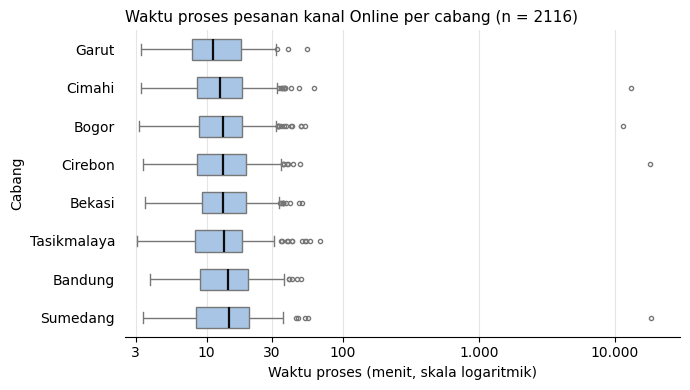

,count,25%,50%,75%,max
cabang,,,,,
Garut,257.0,7.8,11.2,17.9,54.1
Cimahi,298.0,8.4,12.6,18.2,12992.9
Bogor,261.0,8.8,13.1,18.3,11378.6
Cirebon,269.0,8.5,13.1,19.5,18050.5
Bekasi,284.0,9.2,13.2,19.3,50.2
Tasikmalaya,255.0,8.2,13.3,18.2,67.8
Bandung,241.0,8.9,14.4,20.2,49.5
Sumedang,251.0,8.4,14.6,20.5,18474.5


In [28]:
# Gambar 1: kanal Online
waktu_per_cabang("Online", 1)

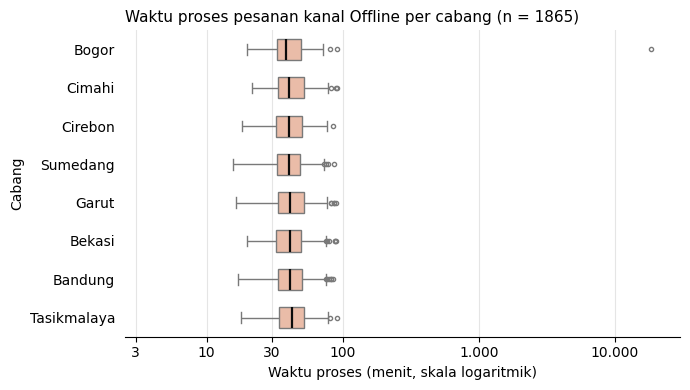

,count,25%,50%,75%,max
cabang,,,,,
Bogor,228.0,32.8,38.5,49.5,18487.0
Cimahi,215.0,33.6,40.1,51.8,90.4
Cirebon,247.0,32.5,40.1,50.4,84.2
Sumedang,237.0,32.6,40.2,48.6,85.9
Garut,241.0,33.6,40.7,51.7,89.3
Bekasi,235.0,32.4,40.9,49.6,88.5
Bandung,230.0,33.3,41.2,50.0,84.2
Tasikmalaya,232.0,34.0,42.7,51.8,90.6


In [29]:
# Gambar 2: kanal Offline
waktu_per_cabang("Offline", 2)

### B2. Rating pelanggan per kanal, lalu per kategori produk

In [30]:
# Rata-rata rating per kanal (baris tanpa rating tidak dihitung)
WARNA_KANAL = {"Online": "#2a78d6", "Offline": "#eb6834"}
rating = df_bersih.dropna(subset=["rating_pelanggan"])
per_kanal = rating.groupby("kanal")["rating_pelanggan"].agg(n="count", rata_rata="mean", sem="sem")
per_kanal.round(3)

,n,rata_rata,sem
kanal,,,
Offline,1750,3.943,0.018
Online,1990,3.687,0.018


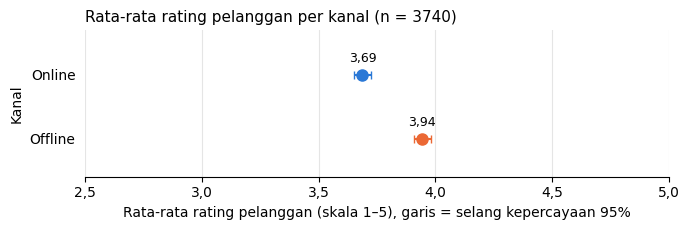

In [31]:
# Gambar 3: rata-rata rating per kanal, garis = selang kepercayaan 95%
fig, ax = plt.subplots(figsize=(7, 2.4))
for k, b in per_kanal.iterrows():
    ax.errorbar(b["rata_rata"], k, xerr=1.96 * b["sem"], fmt="o", color=WARNA_KANAL[k],
                markersize=8, capsize=3, linewidth=1.5)
    ax.annotate(f"{b['rata_rata']:.2f}".replace(".", ","), (b["rata_rata"], k),
                xytext=(0, 9), textcoords="offset points", ha="center", fontsize=9)
ax.set_xlim(2.5, 5)
ax.set_xticks(np.arange(2.5, 5.01, 0.5), ["2,5", "3,0", "3,5", "4,0", "4,5", "5,0"])
ax.set_ylim(-0.6, 1.7)
ax.set_xlabel("Rata-rata rating pelanggan (skala 1–5), garis = selang kepercayaan 95%")
ax.set_ylabel("Kanal")
ax.set_title(f"Rata-rata rating pelanggan per kanal (n = {len(rating)})", loc="left", fontsize=11)
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
sns.despine(left=True)
ax.tick_params(left=False)
fig.tight_layout()
fig.savefig(FOLDER_GAMBAR / "gambar3_rating_per_kanal.png", dpi=200)
plt.show()

In [32]:
# Rata-rata rating per kanal di dalam tiap kategori produk
per_kategori = rating.groupby(["kategori_produk", "kanal"])["rating_pelanggan"].agg(
    n="count", rata_rata="mean", sem="sem")
per_kategori.round(3).unstack("kanal")

n        rata_rata            sem       
kanal           Offline Online   Offline Online Offline Online
kategori_produk                                               
Aksesori             57    544     2.807  3.173   0.092  0.028
Elektronik          462     73     4.368  4.575   0.028  0.061
Makanan Kering      187    730     3.198  3.568   0.054  0.025
Peralatan Rumah     549    144     4.137  4.472   0.027  0.051
Perawatan Diri      495    499     3.743  4.066   0.031  0.030

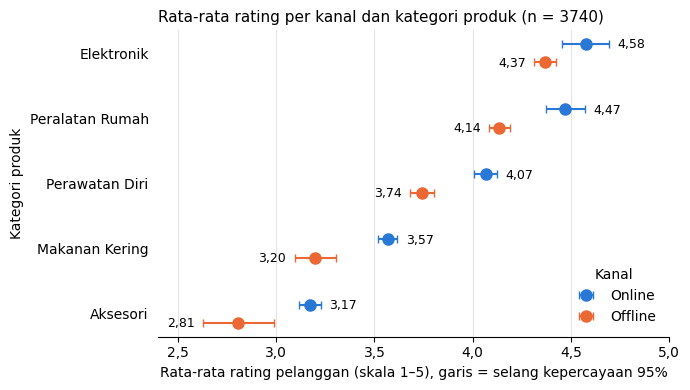

In [33]:
# Gambar 4: rata-rata rating per kanal, dipilah per kategori produk
urutan = rating.groupby("kategori_produk")["rating_pelanggan"].mean().sort_values().index
geser = {"Online": 0.14, "Offline": -0.14}
fig, ax = plt.subplots(figsize=(7, 4))
for kanal in ["Online", "Offline"]:
    b = per_kategori.xs(kanal, level="kanal").loc[urutan]
    y = np.arange(len(urutan)) + geser[kanal]
    ax.errorbar(b["rata_rata"], y, xerr=1.96 * b["sem"], fmt="o", color=WARNA_KANAL[kanal],
                markersize=8, capsize=3, linewidth=1.5, label=kanal)
    arah = 1 if kanal == "Online" else -1  # label di luar ujung garis
    for x, e, yy in zip(b["rata_rata"], 1.96 * b["sem"], y):
        ax.annotate(f"{x:.2f}".replace(".", ","), (x + arah * e, yy), xytext=(6 * arah, -3),
                    textcoords="offset points", ha="left" if arah == 1 else "right", fontsize=9)
ax.set_yticks(np.arange(len(urutan)), urutan)
ax.set_xlim(2.4, 5)
ax.set_xticks(np.arange(2.5, 5.01, 0.5), ["2,5", "3,0", "3,5", "4,0", "4,5", "5,0"])
ax.set_xlabel("Rata-rata rating pelanggan (skala 1–5), garis = selang kepercayaan 95%")
ax.set_ylabel("Kategori produk")
ax.set_title(f"Rata-rata rating per kanal dan kategori produk (n = {len(rating)})", loc="left", fontsize=11)
ax.legend(title="Kanal", frameon=False, loc="lower right")
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
sns.despine(left=True)
ax.tick_params(left=False)
fig.tight_layout()
fig.savefig(FOLDER_GAMBAR / "gambar4_rating_per_kanal_dan_kategori.png", dpi=200)
plt.show()

In [34]:
# Porsi tiap kategori produk di dalam tiap kanal (transaksi berrating) dan rating kategorinya
porsi = pd.crosstab(rating["kategori_produk"], rating["kanal"], normalize="columns").loc[urutan] * 100
rating_kategori = rating.groupby("kategori_produk")["rating_pelanggan"].mean().loc[urutan]
porsi.round(1).assign(rating_kategori=rating_kategori.round(2))

kanal,Offline,Online,rating_kategori
kategori_produk,,,
Aksesori,3.3,27.3,3.14
Makanan Kering,10.7,36.7,3.49
Perawatan Diri,28.3,25.1,3.91
Peralatan Rumah,31.4,7.2,4.21
Elektronik,26.4,3.7,4.40


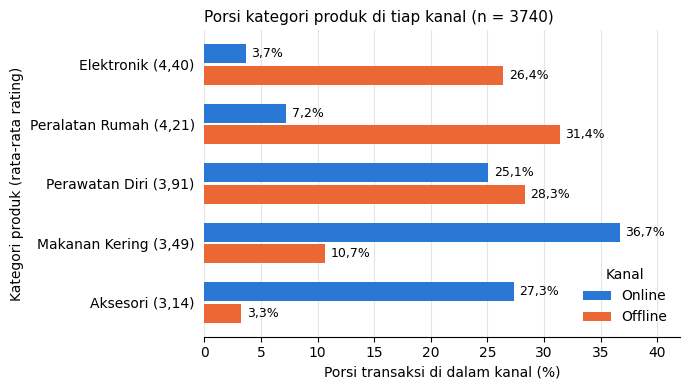

In [35]:
# Gambar 5: porsi kategori produk di tiap kanal
tinggi = 0.36
y = np.arange(len(urutan))
fig, ax = plt.subplots(figsize=(7, 4))
for kanal, arah in [("Online", 1), ("Offline", -1)]:
    posisi = y + arah * tinggi / 2
    ax.barh(posisi, porsi[kanal], height=tinggi - 0.04, color=WARNA_KANAL[kanal], label=kanal)
    for x, yy in zip(porsi[kanal], posisi):
        ax.annotate(f"{x:.1f}%".replace(".", ","), (x, yy), xytext=(4, 0),
                    textcoords="offset points", va="center", fontsize=9)
ax.set_yticks(y, [f"{k} ({r:.2f})".replace(".", ",") for k, r in rating_kategori.items()])
ax.set_xlim(0, 42)
ax.set_xlabel("Porsi transaksi di dalam kanal (%)")
ax.set_ylabel("Kategori produk (rata-rata rating)")
ax.set_title(f"Porsi kategori produk di tiap kanal (n = {len(rating)})", loc="left", fontsize=11)
ax.legend(title="Kanal", frameon=False, loc="lower right")
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
sns.despine(left=True)
ax.tick_params(left=False)
fig.tight_layout()
fig.savefig(FOLDER_GAMBAR / "gambar5_porsi_kategori_per_kanal.png", dpi=200)
plt.show()